# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [1]:
%%writefile heap.py
class Heap:
    """Min-heap implementado con un arreglo y posiciones desde 1."""

    def __init__(self):
        # La posición 0 es un centinela y no pertenece al heap.
        self.arreglo = [float("-inf")]

    def insert(self, valor, imagen=False):
        """Inserta un valor y lo desplaza hacia arriba si es necesario."""
        self.arreglo.append(valor)
        posicion = len(self.arreglo) - 1

        # Percolación hacia arriba.
        while posicion > 1:
            padre = posicion // 2
            if self.arreglo[posicion] < self.arreglo[padre]:
                self.arreglo[posicion], self.arreglo[padre] = (
                    self.arreglo[padre], self.arreglo[posicion]
                )
                posicion = padre
            else:
                break

        if imagen:
            self._dibujar()

    def remove_smallest(self, imagen=False):
        """Elimina y devuelve la raíz, que contiene el menor valor."""
        cantidad = len(self.arreglo) - 1

        if cantidad == 0:
            return None

        menor = self.arreglo[1]

        # Si solo hay un elemento, basta con quitarlo.
        if cantidad == 1:
            self.arreglo.pop()
        else:
            # El último elemento ocupa temporalmente el lugar de la raíz.
            self.arreglo[1] = self.arreglo.pop()
            self._bajar(1)

        if imagen:
            self._dibujar()

        return menor

    def build_heap(self, lista, imagen=False):
        """Construye un min-heap mediante el método de abajo hacia arriba."""
        self.arreglo = [float("-inf")] + list(lista)

        # Las hojas ya son heaps. Se reorganizan los nodos internos
        # empezando por el último padre y terminando en la raíz.
        for posicion in range((len(self.arreglo) - 1) // 2, 0, -1):
            self._bajar(posicion)

        if imagen:
            self._dibujar()

    def _bajar(self, posicion):
        """Restablece la propiedad de min-heap desde una posición hacia abajo."""
        cantidad = len(self.arreglo) - 1

        while 2 * posicion <= cantidad:
            hijo_izquierdo = 2 * posicion
            hijo_derecho = hijo_izquierdo + 1
            hijo_menor = hijo_izquierdo

            # Se escoge el hijo de menor valor. En caso de empate,
            # se conserva el hijo izquierdo.
            if (hijo_derecho <= cantidad and
                    self.arreglo[hijo_derecho] < self.arreglo[hijo_izquierdo]):
                hijo_menor = hijo_derecho

            if self.arreglo[hijo_menor] < self.arreglo[posicion]:
                self.arreglo[posicion], self.arreglo[hijo_menor] = (
                    self.arreglo[hijo_menor], self.arreglo[posicion]
                )
                posicion = hijo_menor
            else:
                break

    def _dibujar(self):
        """Muestra el estado actual del heap como un árbol binario."""
        import matplotlib.pyplot as plt
        from matplotlib.patches import Circle

        cantidad = len(self.arreglo) - 1
        if cantidad == 0:
            fig, ax = plt.subplots(figsize=(5, 1.8))
            ax.text(0.5, 0.5, "Heap vacío", ha="center", va="center", fontsize=13)
            ax.axis("off")
            plt.show()
            return

        ultimo_nivel = cantidad.bit_length() - 1
        espacio_y = 1.5   # separación vertical entre niveles
        radio = 0.4       # las hojas quedan separadas 1 unidad en x

        ancho = max(4, 0.7 * 2 ** ultimo_nivel)
        alto = max(2.5, (ultimo_nivel + 1) * 1.4)
        fig, ax = plt.subplots(figsize=(ancho, alto))

        # Posición de cada nodo, todo en la misma escala.
        posiciones = {}
        for i in range(1, cantidad + 1):
            nivel = i.bit_length() - 1
            columna = i - 2 ** nivel
            x = (columna + 0.5) * 2 ** (ultimo_nivel - nivel)
            y = -nivel * espacio_y
            posiciones[i] = (x, y)

        # Aristas primero, para que queden detrás de los nodos.
        for i in range(1, cantidad + 1):
            x1, y1 = posiciones[i]
            for hijo in (2 * i, 2 * i + 1):
                if hijo <= cantidad:
                    x2, y2 = posiciones[hijo]
                    ax.plot([x1, x2], [y1, y2], color="black",
                            linewidth=1.5, zorder=1)

        # Nodos con su valor.
        for i in range(1, cantidad + 1):
            x, y = posiciones[i]
            ax.add_patch(Circle((x, y), radius=radio, facecolor="white",
                                edgecolor="black", linewidth=1.5, zorder=2))
            ax.text(x, y, str(self.arreglo[i]), ha="center", va="center",
                    fontsize=10, zorder=3)

        ax.set_xlim(0, 2 ** ultimo_nivel)
        ax.set_ylim(-ultimo_nivel * espacio_y - 0.8, 0.8)
        ax.set_aspect("equal")
        ax.axis("off")
        ax.set_title("Min-heap")
        plt.tight_layout()
        plt.show()


Writing heap.py


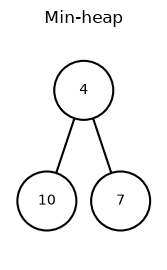

In [2]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)